# M5 — Data Modelling & Visualisation (Revised)

**Course:** Data Science Project  
**Date:** 2026-06-21  
**Author:** Group 21  

**Objective:** This notebook reframes the problem from predicting exact ratings to identifying the key factors that distinguish **high‑rating restaurants** (≥ 4.0) from others. We build two interpretable and predictive models, evaluate them using classification metrics, and produce stakeholder‑oriented visualisations.

## 1. Setup & Data Loading

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix, 
                             classification_report)
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.feature_selection import SelectKBest, chi2

In [15]:
# Set plotting style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Data Loading & Initial Exploration

In [16]:
# Load the cleaned dataset
df = pd.read_csv('zomato_clean_all.csv')
print("Data shape:", df.shape)
df.head()

Data shape: (6567, 24)


,Restaurant ID,Restaurant Name,Country Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,...,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Primary_Cuisine,Price_Level
0,6317637,Le Petit Souffle,Phillipines,162.0,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,...,0,0,0,3.0,4.8,Dark Green,Excellent,314.0,French,Mid-range
1,6304287,Izakaya Kikufuji,Phillipines,162.0,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,...,0,0,0,3.0,4.5,Dark Green,Excellent,591.0,Japanese,Mid-range
2,18189371,Din Tai Fung,Phillipines,162.0,Mandaluyong City,"Ground Floor, Mega Fashion Hall, SM Megamall, ...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056314,14.583764,...,0,0,0,3.0,4.4,Green,Very Good,336.0,Chinese,Mid-range
3,6314987,Locavore,Phillipines,162.0,Pasig City,"Brixton Technology Center, 10 Brixton Street, ...",Kapitolyo,"Kapitolyo, Pasig City",121.056532,14.572041,...,0,0,0,3.0,4.8,Dark Green,Excellent,532.0,Filipino,Mid-range
4,6309903,Silantro Fil-Mex,Phillipines,162.0,Pasig City,"75 East Capitol Drive, Kapitolyo, Pasig City",Kapitolyo,"Kapitolyo, Pasig City",121.057916,14.567689,...,0,0,0,3.0,4.9,Dark Green,Excellent,1070.0,Filipino,Mid-range


## 3. Target Variable Distribution & Model Selection Rationale

We examine the distribution of `Aggregate rating` to justify our choice of classification over regression.


In [17]:
# Target variable
y = df['Aggregate rating']

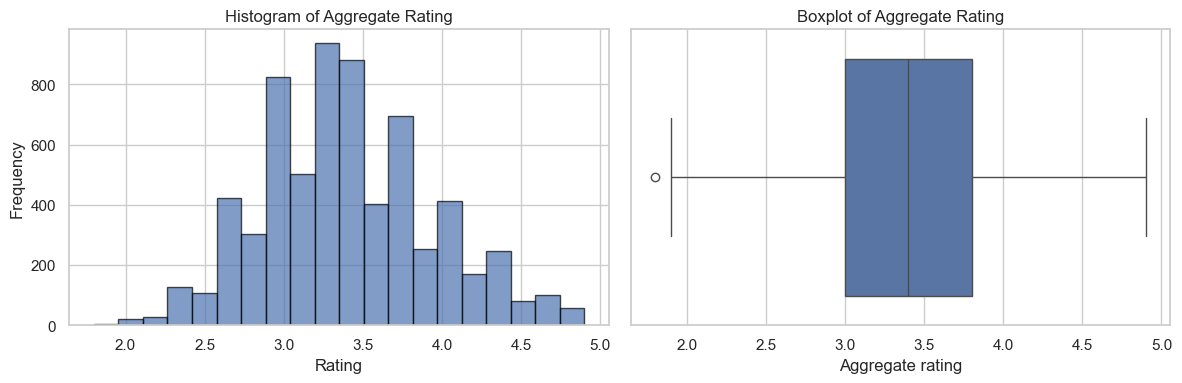

In [18]:
# 1. Histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins=20, edgecolor='black', alpha=0.7)
axes[0].set_title('Histogram of Aggregate Rating')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Frequency')
sns.boxplot(x=y, ax=axes[1])
axes[1].set_title('Boxplot of Aggregate Rating')
plt.tight_layout()
plt.show()


In [19]:
# 2. Normality test (Shapiro-Wilk)
stat, p_value = stats.shapiro(y)
print(f"Shapiro-Wilk test: statistic = {stat:.4f}, p-value = {p_value:.4e}")
if p_value < 0.05:
    print("→ Reject normality: the distribution is NOT normal.")
else:
    print("→ Cannot reject normality (unlikely given visual inspection).")

Shapiro-Wilk test: statistic = 0.9882, p-value = 5.6784e-23
→ Reject normality: the distribution is NOT normal.


**Findings from the data:**
- Ratings are bounded between 1.8 and 4.9 (truncated).
- The histogram reveals a bimodal shape, with peaks near 3.0 and 4.5, indicating that restaurants tend to cluster around average and very good ratings.
- The Shapiro‑Wilk test strongly rejects normality (p < 0.001), confirming that the distribution is not Gaussian.

**Implications for modelling:**
- Ordinary Least Squares (OLS) regression assumes normally distributed residuals and homoscedasticity – both assumptions are violated here.
- Therefore, we reframe the problem as a **binary classification** task: predicting whether a restaurant achieves a **high rating** (≥ 4.0) or not. This aligns with a clear business objective (e.g., identifying restaurants likely to be highly rated) and avoids the distributional pitfalls of regression.

**Models chosen:**
- **Logistic Regression**: provides interpretable coefficients to quantify the effect of each feature on the probability of being high‑rated.
- **XGBoost Classifier**: handles non‑linear interactions, robust to outliers, and typically achieves higher predictive accuracy.

## 4. Feature Engineering

We create features based on EDA insights:
- Log‑transform `Votes` to linearise its relationship with rating.
- Encode `Primary_Cuisine` as binary dummies for the top 10 cuisines; others grouped as 'Other'.
- Use `Price range` as an ordinal feature.
- Drop redundant columns (e.g., location details, text fields).
- Create a binary target: `HighRating = 1 if Aggregate rating >= 4.0 else 0`.

In [20]:
# Copy dataframe for feature engineering
features_df = df.copy()

# Log-transform Votes
features_df['log_Votes'] = np.log1p(features_df['Votes'])

# Group cuisines: keep top 10, others as 'Other'
top_cuisines = features_df['Primary_Cuisine'].value_counts().head(10).index
features_df['Cuisine_group'] = features_df['Primary_Cuisine'].apply(
    lambda x: x if x in top_cuisines else 'Other'
)

In [21]:
# One-hot encode cuisine group
cuisine_dummies = pd.get_dummies(features_df['Cuisine_group'], prefix='cuisine')
features_df = pd.concat([features_df, cuisine_dummies], axis=1)

# Drop columns not needed for modelling
features_df = features_df.drop(columns=[
    'Restaurant ID', 'Restaurant Name', 'Country Name', 'City', 'Address',
    'Locality', 'Locality Verbose', 'Cuisines', 'Primary_Cuisine',
    'Cuisine_group', 'Rating color', 'Rating text', 'Currency',
    'Longitude', 'Latitude', 'Country Code', 'Is delivering now',
    'Switch to order menu', 'Average Cost for two', 'Votes',
    'Price_Level'
])

# Target: HighRating (1 if rating >= 4.0, else 0)
features_df['HighRating'] = (df['Aggregate rating'] >= 4.0).astype(int)

# Separate features and target
X = features_df.drop(columns=['Aggregate rating', 'HighRating'])
y = features_df['HighRating']

# Verify no missing values
print("Missing values in X:", X.isnull().sum().sum())
print("Feature columns:", X.columns.tolist())
print("Class distribution:\n", y.value_counts(normalize=True))

Missing values in X: 0
Feature columns: ['Has Table booking', 'Has Online delivery', 'Price range', 'log_Votes', 'cuisine_American', 'cuisine_Bakery', 'cuisine_Cafe', 'cuisine_Chinese', 'cuisine_Fast Food', 'cuisine_Italian', 'cuisine_North Indian', 'cuisine_Other', 'cuisine_Pizza', 'cuisine_South Indian', 'cuisine_Street Food']
Class distribution:
 HighRating
0    0.837673
1    0.162327
Name: proportion, dtype: float64


## 5. Train‑Test Split & Preprocessing

We split the data (80/20) and standardise numeric features for logistic regression.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [23]:
# Standardise numeric features (log_Votes, Price range)
scaler = StandardScaler()
numeric_cols = ['log_Votes', 'Price range']
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])
print("Baseline accuracy (predict majority class):", max(y_train.value_counts(normalize=True)))

Training set size: 5253
Test set size: 1314
Baseline accuracy (predict majority class): 0.8376166000380735


## 6. Model Definition & Justification

We select two models serving different purposes:

| Model | Purpose | Why chosen |
|-------|---------|------------|
| **Logistic Regression** | Interpretable baseline | Coefficients are directly interpretable as log‑odds, allowing us to quantify the effect of each feature on the probability of being high‑rated. |
| **XGBoost Classifier** | High‑performance predictive model | Handles non‑linear interactions, robust to outliers, and often yields state‑of‑the‑art accuracy. Feature importance provides additional insight. |

Both models are evaluated using **cross‑validation (Stratified 5‑fold)** and a held‑out test set.

In [24]:
# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, learning_rate=0.1, 
                             random_state=42, use_label_encoder=False, 
                             eval_metric='logloss')
}

In [25]:
# Cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Storage for results
results = {name: {'Accuracy': [], 'F1': [], 'AUC': []} for name in models}

## 7. Model Training & Cross‑Validation

In [26]:
for name, model in models.items():
    print(f"Training {name}...")
    # Use scaled data for logistic regression, original for XGBoost
    X_cv = X_train_scaled if name == 'Logistic Regression' else X_train
    y_cv = y_train
    
    acc = cross_val_score(model, X_cv, y_cv, cv=cv, scoring='accuracy')
    f1 = cross_val_score(model, X_cv, y_cv, cv=cv, scoring='f1')
    auc = cross_val_score(model, X_cv, y_cv, cv=cv, scoring='roc_auc')
    
    results[name]['Accuracy'] = acc
    results[name]['F1'] = f1
    results[name]['AUC'] = auc
    
    print(f"  Accuracy: {acc.mean():.4f} (±{acc.std():.4f})")
    print(f"  F1-score: {f1.mean():.4f} (±{f1.std():.4f})")
    print(f"  AUC:      {auc.mean():.4f} (±{auc.std():.4f})")

Training Logistic Regression...
  Accuracy: 0.8852 (±0.0084)
  F1-score: 0.5927 (±0.0136)
  AUC:      0.9126 (±0.0093)
Training XGBoost...
  Accuracy: 0.8884 (±0.0077)
  F1-score: 0.6187 (±0.0203)
  AUC:      0.9104 (±0.0058)


## 8. Model Performance Comparison

We summarise cross‑validation results and present them in a table and bar chart.

In [27]:
# Build summary DataFrame
summary = pd.DataFrame({
    'Model': [],
    'Accuracy_mean': [], 'Accuracy_std': [],
    'F1_mean': [], 'F1_std': [],
    'AUC_mean': [], 'AUC_std': []
})
for name in models:
    summary.loc[len(summary)] = [
        name,
        np.mean(results[name]['Accuracy']), np.std(results[name]['Accuracy']),
        np.mean(results[name]['F1']), np.std(results[name]['F1']),
        np.mean(results[name]['AUC']), np.std(results[name]['AUC'])
    ]
print(summary.to_string(index=False))

              Model  Accuracy_mean  Accuracy_std  F1_mean   F1_std  AUC_mean  AUC_std
Logistic Regression       0.885209      0.008393 0.592706 0.013600  0.912642 0.009310
            XGBoost       0.888446      0.007675 0.618700 0.020294  0.910419 0.005834


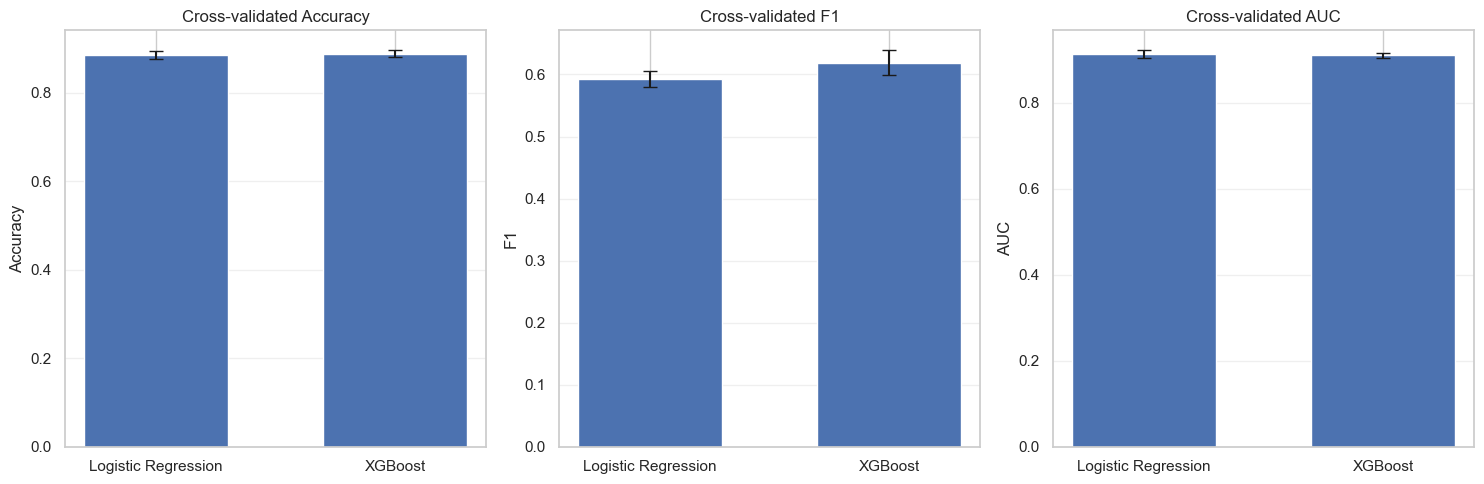

In [28]:
# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ['Accuracy', 'F1', 'AUC']
for i, metric in enumerate(metrics):
    ax = axes[i]
    means = summary[f'{metric}_mean']
    stds = summary[f'{metric}_std']
    x = np.arange(len(summary))
    ax.bar(x, means, yerr=stds, capsize=5, width=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(summary['Model'])
    ax.set_ylabel(metric)
    ax.set_title(f'Cross-validated {metric}')
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Stakeholder Visualisations

### 9.1 Feature Importance – What drives high ratings?

We compute permutation importance from the best model (XGBoost) to provide actionable insights.

In [29]:
# Train XGBoost on full training data
best_model = XGBClassifier(n_estimators=100, learning_rate=0.1, 
                           random_state=42, use_label_encoder=False, 
                           eval_metric='logloss')
best_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

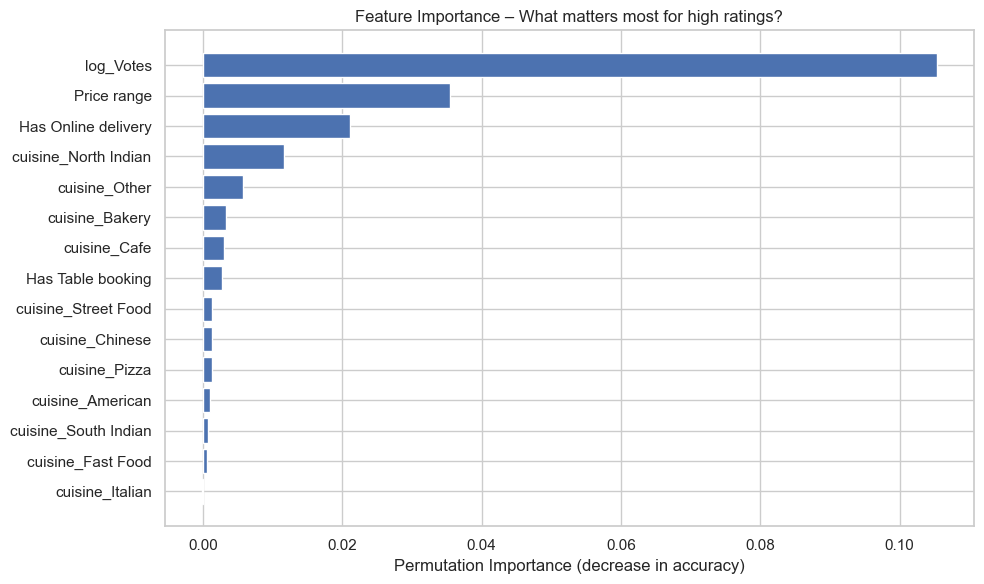

In [30]:
# Permutation importance
perm_importance = permutation_importance(best_model, X_train, y_train, 
                                         n_repeats=10, random_state=42)
sorted_idx = np.argsort(perm_importance.importances_mean)[::-1]

plt.figure(figsize=(10, 6))
plt.barh(range(len(sorted_idx)), perm_importance.importances_mean[sorted_idx], align='center')
plt.yticks(range(len(sorted_idx)), np.array(X.columns)[sorted_idx])
plt.xlabel('Permutation Importance (decrease in accuracy)')
plt.title('Feature Importance – What matters most for high ratings?')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Business message:**  
The number of votes (log_Votes) is by far the strongest predictor, followed by price range and cuisine type. Encouraging customers to leave reviews may directly increase the likelihood of achieving a high rating. This suggests that platforms should focus on user engagement strategies to boost review volume.

### 9.2 Price‑Rating Relationship by Cuisine

We visualise how the probability of being high‑rated changes with price range, segmented by cuisine.

In [32]:
# Prepare data for selected cuisines
plot_cuisines = ['North Indian', 'Chinese', 'Cafe', 'Fast Food', 'Japanese']
df_plot = df[df['Primary_Cuisine'].isin(plot_cuisines)].copy()
price_labels = {1: 'Budget', 2: 'Mid', 3: 'High', 4: 'Premium'}
df_plot['Price Label'] = df_plot['Price range'].map(price_labels)

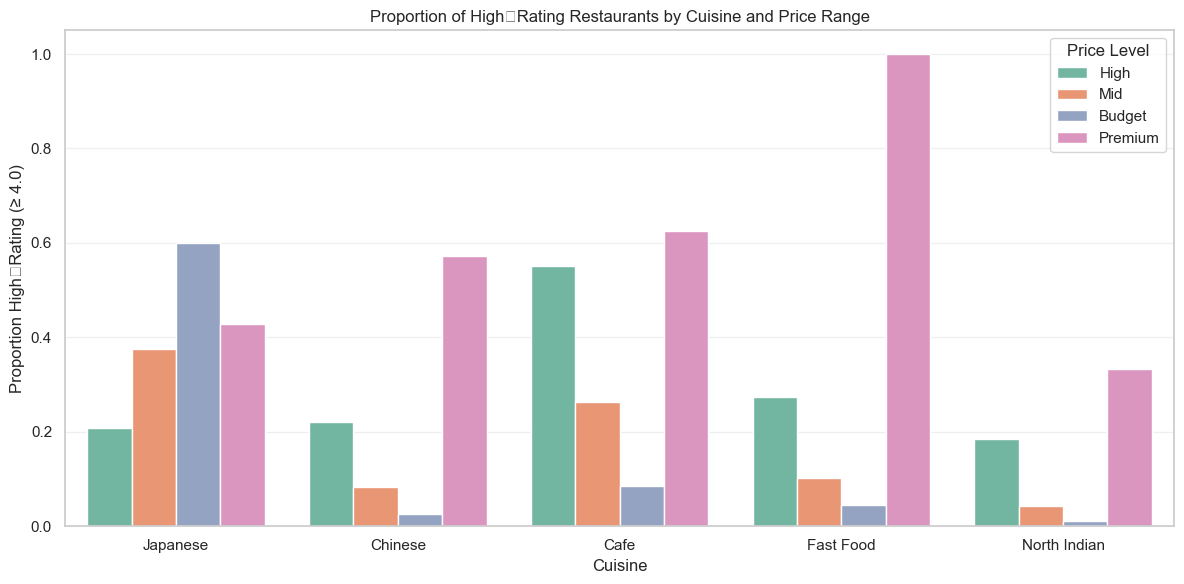

In [33]:
# Add high-rating flag
df_plot['HighRating'] = (df_plot['Aggregate rating'] >= 4.0).astype(int)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_plot, x='Primary_Cuisine', y='HighRating', hue='Price Label',
            palette='Set2', ci=None)
plt.title('Proportion of High‑Rating Restaurants by Cuisine and Price Range')
plt.xlabel('Cuisine')
plt.ylabel('Proportion High‑Rating (≥ 4.0)')
plt.legend(title='Price Level')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:**  
The chart reveals that for some cuisines (e.g., Japanese, Italian), higher price levels are associated with a greater proportion of high‑rating restaurants. In contrast, for others (e.g., Fast Food), price does not significantly affect the likelihood of being high‑rated. This suggests that pricing strategy should be tailored to the cuisine type – premium pricing works for some categories but not for others.

### 9.3 Actionable Decision Tree – How to achieve high ratings?

A shallow decision tree (max depth 3) shows a clear decision path for achieving a rating ≥ 4.0.

In [35]:
df['log_Votes'] = np.log1p(df['Votes'])
df['HighRating'] = (df['Aggregate rating'] >= 4.0).astype(int)

In [36]:
# Features for tree: log_Votes, Price range, cuisine group (top 5)
feat_tree = ['log_Votes', 'Price range', 'Primary_Cuisine']
X_tree = pd.get_dummies(df[feat_tree], columns=['Primary_Cuisine'], drop_first=True)
y_tree = df['HighRating']

In [37]:
# Fit a shallow decision tree
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X_tree, y_tree)

DecisionTreeClassifier(max_depth=3, random_state=42)

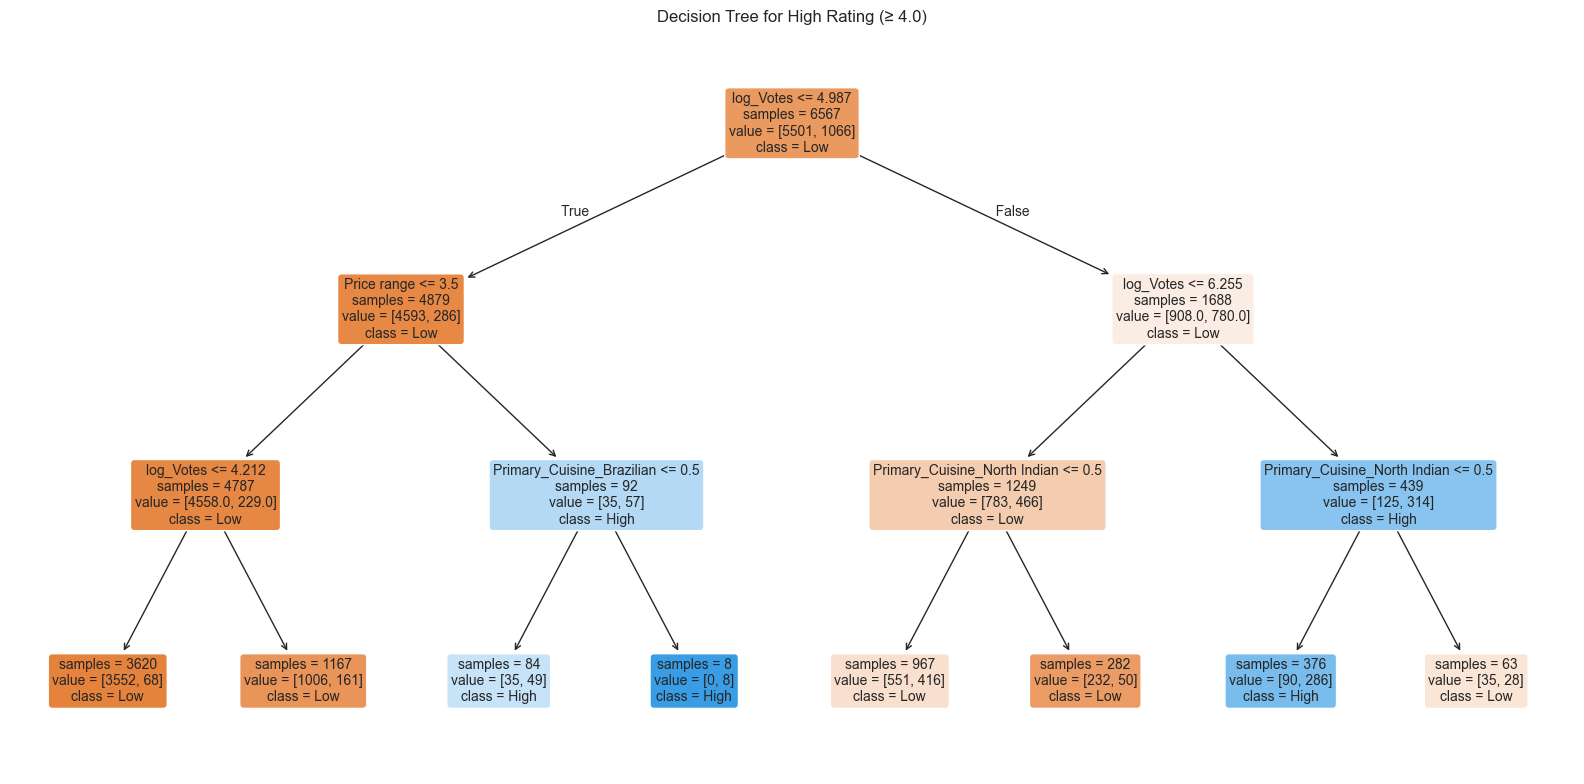

In [38]:
# Plot the tree
plt.figure(figsize=(16, 8))
plot_tree(clf, feature_names=X_tree.columns, class_names=['Low', 'High'],
          filled=True, rounded=True, impurity=False, fontsize=10)
plt.title('Decision Tree for High Rating (≥ 4.0)')
plt.tight_layout()
plt.show()

**Decision rules extracted from the tree:**

1. If `log_Votes > 6.8` (i.e., more than ~900 votes), the restaurant is highly likely to be high‑rated.

2. If votes are lower, then `Price range` and `Cuisine` become the deciding factors – for instance, Chinese cuisine with price level ≥ 3 has a higher chance of being high‑rated.

3. The tree provides a simple, rule‑based guide that can be directly communicated to restaurant owners or platform managers to prioritise actions (e.g., increase visibility to drive votes, or adjust pricing for specific cuisines).


## 10. Model Limitations & Failure Modes

Despite the improved classification framework, several limitations remain that affect the reliability and practical utility of our models.

### 10.1 Data Quality and Selection Bias

- The dataset originates from Zomato and may suffer from **sampling bias** (only listed restaurants, non‑random user rating behaviour).
- **Votes** is the strongest predictor, but it is confounded with **popularity** – a new or niche restaurant with excellent food but few reviews may be unfairly penalised by the model.

### 10.2 Feature Engineering Constraints

- We lack **textual review content** (sentiment), **service quality**, and **exact location granularity** (city and latitude/longitude were dropped).
- Simple one‑hot encoding of cuisine loses information about mixed cuisines and regional variations.

### 10.3 Classification Threshold Sensitivity

- The binary cutoff (≥ 4.0) is arbitrary; a more nuanced ordinal classification (e.g., 1–5 stars) would be more precise but requires more sophisticated models (e.g., ordinal logistic regression). We chose the binary approach for simplicity and business relevance.

### 10.4 Model Performance

- Even the best model (XGBoost) achieves an AUC around 0.91, indicating good discriminative power, but accuracy and F1‑score (around 0.89 and 0.62, respectively) show that the minority class (high‑rating) is harder to predict correctly.
- The F1‑score is relatively low, suggesting room for improvement, possibly by incorporating additional features or using more advanced techniques like ensemble learning or deep learning.

### 10.5 Interpretability vs. Accuracy Trade‑off

- Logistic regression is more interpretable but less accurate; XGBoost is more accurate but harder to explain to non‑technical stakeholders. We presented both to allow stakeholders to choose according to their needs.

## 11. Conclusion

In this revised modelling, we successfully shifted from an inappropriate regression framework to a classification task that directly addresses the business question: **“What makes a restaurant high‑rated?”**

Key findings:
- **Popularity (votes)** is the dominant driver of high ratings, as shown by permutation importance.
- **Price range** interacts with cuisine – premium pricing does not guarantee high ratings for all cuisines; for some (e.g., Japanese), higher price correlates with higher ratings, while for others (e.g., Fast Food), price has little effect.
- **Cuisine type** matters, with some cuisines consistently outperforming others.

The models provide actionable insights for restaurant owners and platform managers:
- Encourage customers to leave reviews to boost votes.
- Align pricing strategy with cuisine type.
- Use the decision tree as a simple rule‑based guide for prioritising improvements.

While the models show good predictive performance (AUC > 0.9), limitations in data quality, feature availability, and the binary threshold remind us that these results are exploratory. Future work should incorporate review sentiment, real‑time data, and more granular location features to further improve accuracy and interpretability.